# Machine Learning Fundamentals
## Unit 05 — Missing Values

**Stage 2: Machine Learning | Beginner level | English B2**  
**Business scenario:** Melbourne house-price estimation  
**Environment:** Google Colab / Jupyter Notebook  
**Libraries:** Pandas, NumPy, Matplotlib, scikit-learn

---

## Business question

The property dataset contains incomplete records. Should we delete features with missing values, fill the gaps, or preserve information about which values were missing?

In this lesson, we will compare three strategies using the same training/validation split and the same Random Forest model. We will use Mean Absolute Error (MAE) to compare their predictive performance.

### Learning outcomes

By the end of this notebook, you should be able to:

- Explain why missing values occur and why they are not the same as zero.
- Identify missing values and summarize their frequency.
- Compare dropping columns, imputation, and missingness indicators.
- Use `SimpleImputer` correctly.
- Evaluate preprocessing strategies using validation MAE.
- Explain how fitting preprocessing on training data only helps prevent data leakage.

### Lesson map

1. Introduction to missing values
2. Three approaches
3. Prepare and inspect the dataset
4. Define a consistent evaluation function
5. Compare the approaches
6. Practical challenge and readiness check

**Dataset:** the provided `melb_data.csv` file. In Google Colab, upload it to the session before running the data-loading cell. The file should be in the notebook's current working directory.

---
# 1. Introduction

There are many ways data can end up with missing values. For example:

- A 2 bedroom house won't include a value for the size of a third bedroom.
- A survey respondent may choose not to share their income.
- A value may not have been recorded correctly during data collection.

Most machine learning libraries, including scikit-learn, require missing values to be handled before many models can be trained. You need to choose a strategy that fits the data and the task.

A missing value in a pandas DataFrame is often shown as `NaN`. It means that a value is not available; it does not mean that the value is zero.


---
# 2. Three Approaches

## Approach 1 — Drop Columns with Missing Values

The simplest option is to drop columns that contain missing values. This may be reasonable when a feature has little value, but it can discard useful information. The illustration below introduces the idea.

<div align="center">
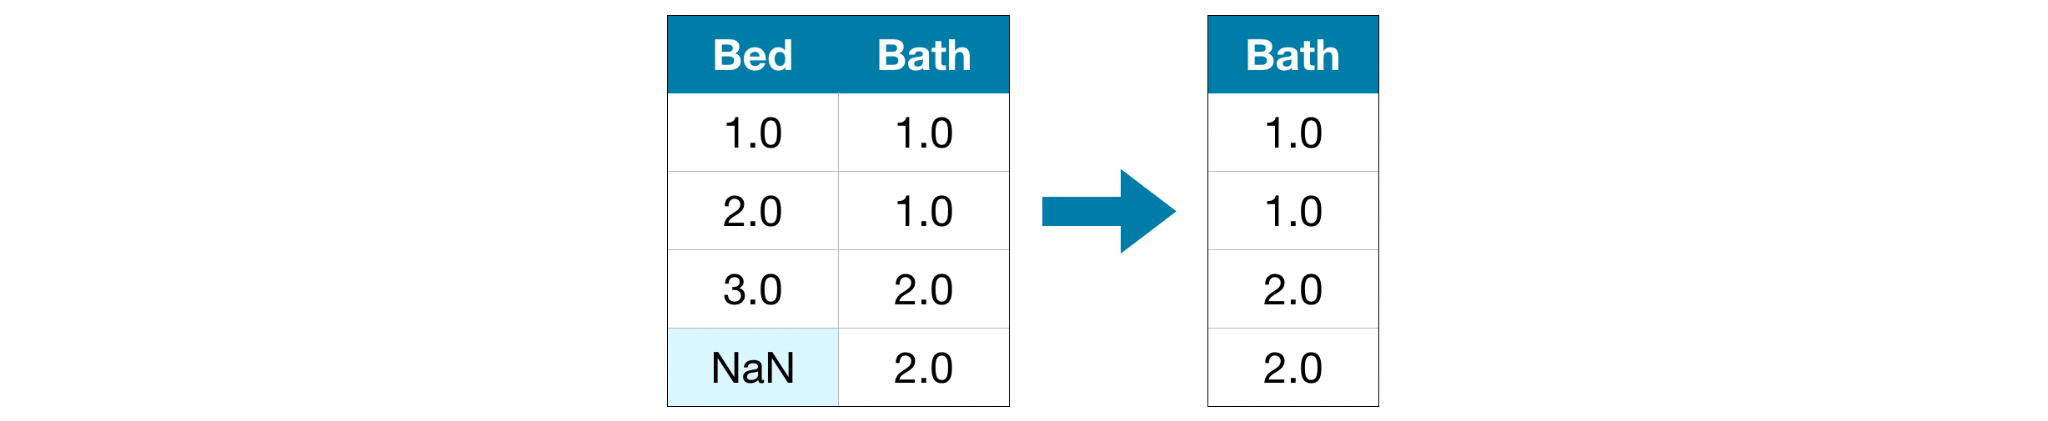
</div>

Unless most values in the dropped columns are missing, the model loses access to a lot of potentially useful information with this approach. As an extreme example, consider a dataset with 10,000 rows, where one important column is missing a single entry. This approach would drop the column entirely.

## Approach 2 — Imputation

Imputation fills in missing values with a replacement value. For instance, we can fill in the mean value along each numeric column.

<div align="center">
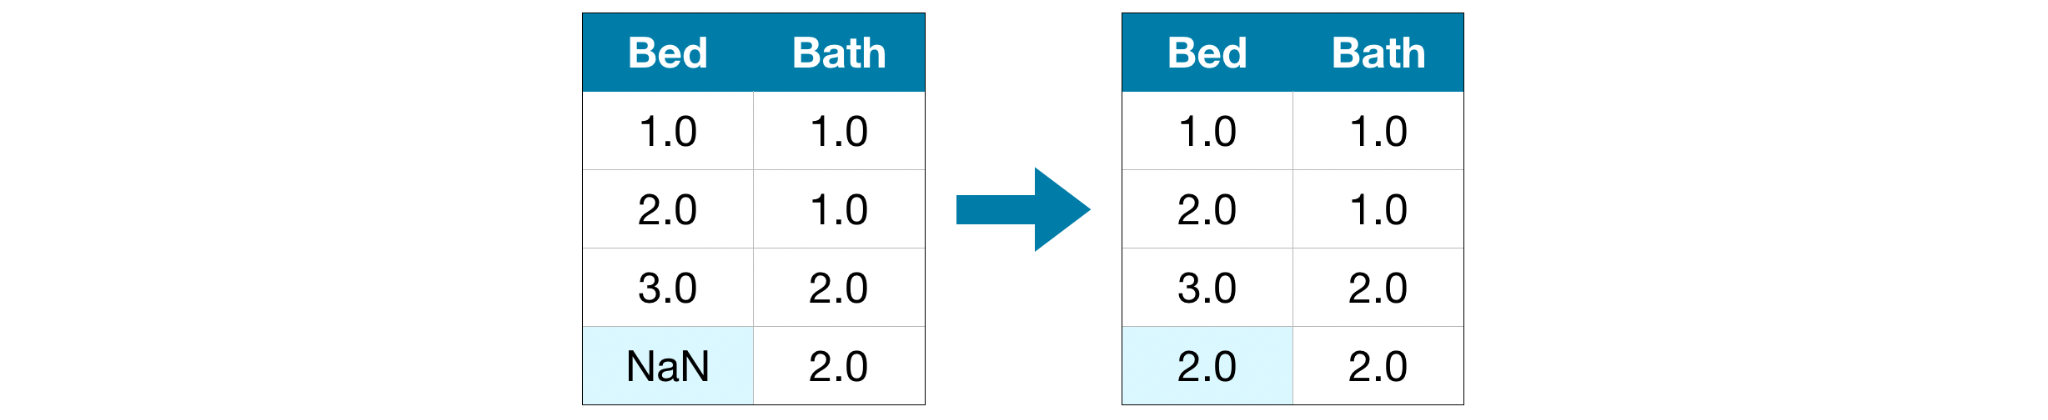
</div>

The imputed value won't be exactly right in most cases, but it usually leads to more accurate models than dropping a useful column. The mean is one option; the median or a constant value may be more suitable for some datasets.

## Approach 3 — Imputation with a Missingness Indicator

Imputation is a standard approach and it often works well. However, the missing values may carry useful information. For example, houses with an unrecorded building area may differ from houses where the area was recorded.

In this approach, we impute the missing values and add a new indicator column for each feature that had missing values in the training data.

<div align="center">
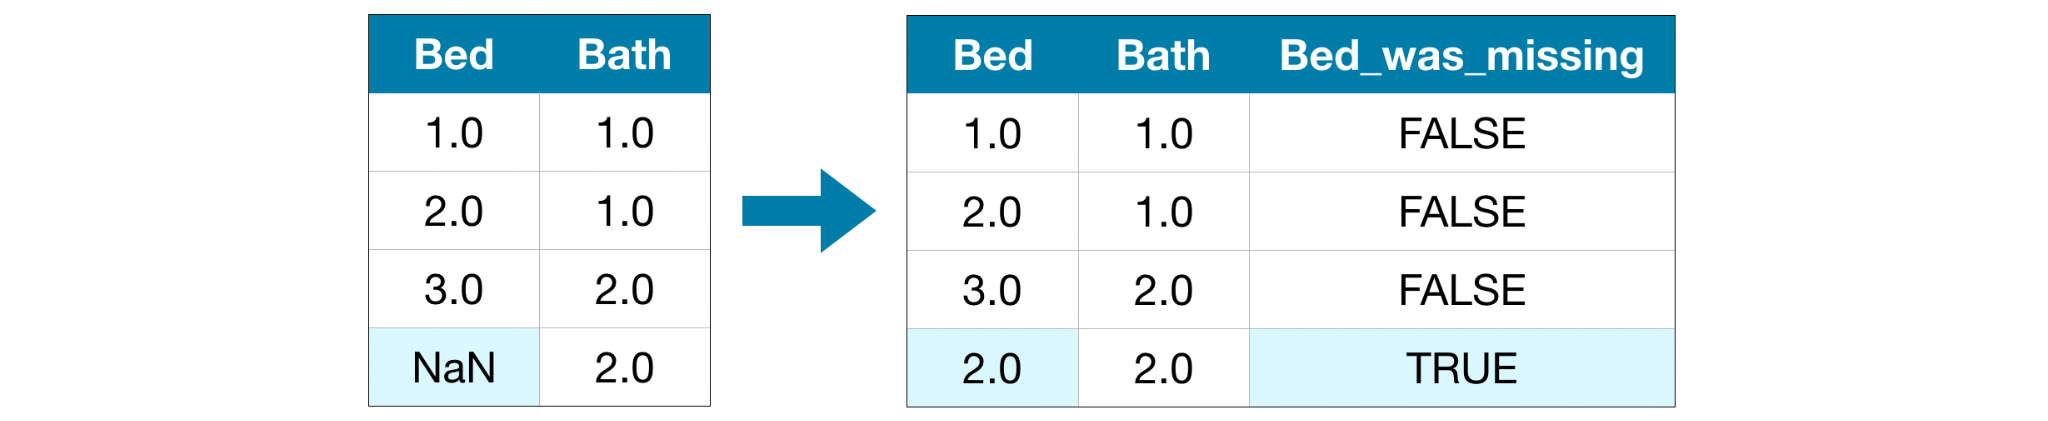
</div>

The indicator records whether the original value was missing. In some cases, this improves results. In other cases, it does not help.


## 2.1 Compare the Approaches

| Approach | What happens? | Possible advantage | Possible limitation |
|---|---|---|---|
| Drop columns | Remove any feature with missing values | Simple and fast | May discard useful information |
| Imputation | Replace missing values with a statistic, such as the mean | Keeps the feature and most rows | Replacement values may not reflect the true values |
| Imputation + indicator | Impute values and add a missingness flag | May preserve useful information about missingness | Extra columns may not improve the model |

There is no single best strategy for every dataset. We will compare the approaches using validation MAE.


---
# 3. Prepare the Data

In this example, we will work with the Melbourne Housing dataset. Our model will use information such as the number of rooms and land size to predict home price.

We won't focus on the data-loading step. Instead, the following code prepares the target, keeps numeric features, and splits the data into training and validation subsets.

**Important:** We split the data before fitting an imputer. Any statistics used to fill missing values must be learned from the training set only. The same fitted imputer is then applied to validation data. This helps prevent data leakage.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Load the data
melbourne_file_path = 'melb_data.csv'
data = pd.read_csv(melbourne_file_path)

# Select target
y = data.Price

# To keep things simple, use only numerical predictors
melb_predictors = data.drop(['Price'], axis=1)
X = melb_predictors.select_dtypes(exclude=['object'])

# Divide data into training and validation subsets
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    train_size=0.8,
    test_size=0.2,
    random_state=0
)

print("Training data shape:", X_train.shape)
print("Validation data shape:", X_valid.shape)

## 3.1 Audit missing values before choosing a strategy

Before changing the data, quantify the missingness. A count shows how many values are missing; a percentage makes it easier to compare columns of different sizes. This inspection should inform the decision rather than applying a strategy automatically.

In [ ]:
missing_summary = pd.DataFrame({
    "missing_count": X_train.isna().sum(),
    "missing_percent": (X_train.isna().mean() * 100).round(2)
})
missing_summary = missing_summary[missing_summary["missing_count"] > 0].sort_values(
    "missing_count", ascending=False
)
display(missing_summary)

## 3.1 Find the Columns with Missing Values

We first identify columns that contain at least one missing value in the training data. We'll use this list in Approach 1 and Approach 3.


In [ ]:
# Find columns with missing values in the training data
cols_with_missing = [
    col for col in X_train.columns
    if X_train[col].isnull().any()
]

print("Columns with missing values:")
print(cols_with_missing)

print("\nMissing values by column:")
missing_val_count_by_column = X_train.isnull().sum()
print(missing_val_count_by_column[missing_val_count_by_column > 0])

---
# 4. Define a Model Evaluation Function

We define a function `score_dataset()` to compare different approaches to dealing with missing values. This function trains a Random Forest model and returns the Mean Absolute Error (MAE) on the validation data.

MAE is the average absolute difference between the actual and predicted house prices. A lower MAE means smaller average prediction errors on the validation set.


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

def score_dataset(X_train_processed, X_valid_processed, y_train, y_valid):
    model = RandomForestRegressor(
        n_estimators=10,
        random_state=0,
        n_jobs=-1
    )
    model.fit(X_train_processed, y_train)
    predictions = model.predict(X_valid_processed)
    return mean_absolute_error(y_valid, predictions)

---
# 5. Compare the Approaches

## Approach 1 — Drop Columns with Missing Values

Since we are working with both training and validation sets, we must drop the same columns from both DataFrames.


In [ ]:
# Drop the same columns from training and validation data
reduced_X_train = X_train.drop(cols_with_missing, axis=1)
reduced_X_valid = X_valid.drop(cols_with_missing, axis=1)

mae_drop = score_dataset(
    reduced_X_train, reduced_X_valid, y_train, y_valid
)

print("MAE from Approach 1 (Drop columns with missing values):")
print(f"${mae_drop:,.2f}")

The original course example reports an MAE of approximately **183,550** for this approach. Your score may differ because the dataset version, feature selection, scikit-learn version, and model settings can affect results. Use the value printed by your own run when discussing this notebook.


## Approach 2 — Imputation

Next, we use `SimpleImputer` to replace missing values with the mean value along each numeric column.

We call `fit_transform()` on the training data to learn the replacement values and apply them. We call `transform()` on the validation data so it uses the same replacement values.


In [ ]:
from sklearn.impute import SimpleImputer

# Create the imputer
my_imputer = SimpleImputer(strategy='mean')

# Fit on training data and transform it
imputed_X_train = pd.DataFrame(
    my_imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Apply the already-fitted imputer to validation data
imputed_X_valid = pd.DataFrame(
    my_imputer.transform(X_valid),
    columns=X_valid.columns,
    index=X_valid.index
)

mae_imputation = score_dataset(
    imputed_X_train, imputed_X_valid, y_train, y_valid
)

print("MAE from Approach 2 (Imputation):")
print(f"${mae_imputation:,.2f}")

The original course example reports an MAE of approximately **178,166** for this approach. In that example, mean imputation performed better than dropping columns. Confirm whether this pattern appears in your own run before drawing a conclusion.

Mean imputation is simple, but it is not always the best choice. For numeric features with strong outliers, the median may be worth testing as well.


## Approach 3 — Imputation with Missingness Indicators

Next, we impute the missing values and keep track of which values were missing originally. We create a new indicator column for each feature that had missing values in the training set.


In [ ]:
# Make copies so the original data remains unchanged
X_train_plus = X_train.copy()
X_valid_plus = X_valid.copy()

# Add indicators for columns that had missing values in training data
for col in cols_with_missing:
    X_train_plus[col + '_was_missing'] = X_train_plus[col].isnull()
    X_valid_plus[col + '_was_missing'] = X_valid_plus[col].isnull()

# Fit the imputer on training data only
my_imputer = SimpleImputer(strategy='mean')

imputed_X_train_plus = pd.DataFrame(
    my_imputer.fit_transform(X_train_plus),
    columns=X_train_plus.columns,
    index=X_train_plus.index
)

imputed_X_valid_plus = pd.DataFrame(
    my_imputer.transform(X_valid_plus),
    columns=X_valid_plus.columns,
    index=X_valid_plus.index
)

mae_imputation_indicator = score_dataset(
    imputed_X_train_plus,
    imputed_X_valid_plus,
    y_train,
    y_valid
)

print("MAE from Approach 3 (Imputation + missingness indicators):")
print(f"${mae_imputation_indicator:,.2f}")

The original course example reports an MAE of approximately **178,928** for this approach. In that example, the indicators did not improve on mean imputation alone. This result is specific to that experiment.

This result does not mean missingness indicators are always unhelpful. It means they did not improve the score in this particular comparison. Always compare the approaches on your data.


## 5.1 Compare the Results

The following are the reference scores reported in the original lesson. They are included to help you interpret the experiment; your executed results are the ones to use for your environment.


In [ ]:
results_df = pd.DataFrame({
    "Approach": [
        "Drop columns with missing values",
        "Mean imputation",
        "Mean imputation + indicators"
    ],
    "Validation MAE (AUD)": [
        mae_drop,
        mae_imputation,
        mae_imputation_indicator
    ]
}).sort_values("Validation MAE (AUD)").reset_index(drop=True)

display(results_df.style.format({"Validation MAE (AUD)": "AUD {:,.0f}"}))

best_approach = results_df.iloc[0]
print(
    f"Best approach in this run: {best_approach['Approach']} "
    f"(Validation MAE: AUD {best_approach['Validation MAE (AUD)']:,.0f})"
)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(results_df["Approach"], results_df["Validation MAE (AUD)"])
ax.set_title("Validation MAE by Missing-Value Strategy")
ax.set_ylabel("Mean Absolute Error (AUD)")
ax.tick_params(axis="x", rotation=12)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**How to interpret the comparison:** Use the dynamically generated table and chart above as the results of your current run. Lower MAE indicates smaller average absolute errors on this validation set. The reference values below are historical course examples, not expected outputs that every environment must reproduce.

| Approach | Reference MAE | Interpretation |
|---|---:|---|
| 1. Drop columns with missing values | $183,550 | Highest error among the three reference results |
| 2. Mean imputation | $178,166 | Lowest error in this comparison |
| 3. Mean imputation + indicators | $178,928 | Slightly higher error than Approach 2 |

In this example, **Approach 2 — Imputation** performed best because it had the lowest validation MAE.


## 5.2 Why Did Imputation Perform Better Here?

The training data in the original example has **10,864 rows and 12 columns**, where three columns contain missing data. The reported missing-value counts are:

- `Car`: 49 missing values
- `BuildingArea`: 5,156 missing values
- `YearBuilt`: 4,307 missing values

Dropping all three columns removes potentially useful information from every row. Imputation preserves those features, which helps explain why it performed better in this comparison.

You can inspect the actual shapes and missing-value counts from your own dataset by running the cells above.


---
# 6. Conclusion and Practice

There are three common ways to handle missing values in this lesson:

- **Drop columns** when a feature is not useful enough to justify keeping it or when missingness makes it unsuitable.
- **Impute missing values** to preserve useful features and rows.
- **Add missingness indicators** when the fact that a value is missing may itself contain useful information.

The results depend on the dataset. Use validation data to compare reasonable approaches, and always fit preprocessing steps on training data only. Scikit-learn's `SimpleImputer` supports strategies such as mean, median, most frequent, and constant replacement. <https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html>


## Your Turn

Compare these approaches to dealing with missing values yourself in the Kaggle exercise.

**[Open Kaggle — Intermediate Machine Learning: Missing Values](https://www.kaggle.com/learn/intermediate-machine-learning/lesson/2)**

[Open the full Intermediate Machine Learning course](https://www.kaggle.com/learn/intermediate-machine-learning)

### Practical challenge

1. Run all three approaches and record their MAE scores.
2. Identify which approach performs best on your validation data.
3. Try `strategy='median'` instead of `strategy='mean'`.
4. Explain why the imputer is fitted on training data and only transformed on validation data.
5. Write a short recommendation for how you would handle missing values in this dataset.

### Practice checklist

- [ ] I can identify missing values in a DataFrame.
- [ ] I can explain the difference between dropping and imputing.
- [ ] I can use `SimpleImputer`.
- [ ] I can create missingness indicator columns.
- [ ] I can compare approaches using validation MAE.
- [ ] I can explain how to avoid data leakage during preprocessing.

## Key takeaway

**Do not remove or replace missing values automatically without checking the effect. Compare reasonable strategies and choose based on validation performance.**


---
## References

- [Kaggle — Intermediate Machine Learning: Missing Values](https://www.kaggle.com/learn/intermediate-machine-learning/lesson/2)
- [scikit-learn — SimpleImputer documentation](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html)
- [scikit-learn — Common pitfalls and data leakage](https://scikit-learn.org/stable/common_pitfalls.html)
